# Question 4

## Setup

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import pyLDAvis
import pyLDAvis.gensim_models
import seaborn as sns
from gensim.corpora import Dictionary
from gensim.models import CoherenceModel, LdaModel

# Folder layout: notebooks/ (this folder), ../data, ../deployment; plots go to outputs/
DATA_DIR = Path('../data')
OUT_DIR = Path('outputs')
OUT_DIR.mkdir(exist_ok=True)

RANDOM_STATE = 42
CHUNK_SIZE = 120
TOPIC_COUNTS = range(2, 7)
pd.set_option('display.width', 200)
pd.set_option('display.max_columns', 20)

## Load cleaned articles saved in Question 3

In [2]:
CLEAN_PATH = DATA_DIR / 'research_corpus_clean.pkl'
if not CLEAN_PATH.exists():
    raise FileNotFoundError('research_corpus_clean.pkl not found: run question_3.ipynb first.')

articles = pd.read_pickle(CLEAN_PATH)
print(f'{len(articles)} articles loaded')
articles[['filename', 'title', 'n_words']].assign(n_clean_tokens=articles['tokens'].str.len())

5 articles loaded


,filename,title,n_words,n_clean_tokens
0,research_1.txt,"[untitled] ""The purposes of this article are t...",5602,1365
1,research_2.txt,"Now I see it, now I don’t: researcher’s positi...",2416,1079
2,research_3.txt,DEVELOPMENTAL RESEARCH: STUDIES OF INSTRUCTION...,3828,1816
3,research_4.txt,"[untitled] ""Cronbach’s alpha is a statistic co...",5922,2718
4,research_5.txt,Denzin’s Paradigm Shift: Revisiting Triangulat...,4027,1742


## 4.1 LDA topic discovery
### Chunking

In [3]:
def make_chunks(documents):
    """Split articles into paragraph-sized pseudo-documents for stable LDA."""
    chunks, chunk_sources = [], []
    for _, article in documents.iterrows():
        tokens = article['tokens']
        for start in range(0, len(tokens), CHUNK_SIZE):
            chunk = tokens[start:start + CHUNK_SIZE]
            if len(chunk) >= CHUNK_SIZE // 2:
                chunks.append(chunk)
                chunk_sources.append(article['filename'])
    return chunks, chunk_sources


def train_lda(corpus, dictionary, n_topics):
    return LdaModel(
        corpus=corpus, id2word=dictionary, num_topics=n_topics,
        passes=30, iterations=400, alpha='auto', eta='auto',
        random_state=RANDOM_STATE,
    )


chunks, chunk_sources = make_chunks(articles)
dictionary = Dictionary(chunks)
dictionary.filter_extremes(no_below=2, no_above=0.70)
corpus = [dictionary.doc2bow(chunk) for chunk in chunks]
if not len(dictionary) or not any(corpus):
    raise ValueError('No usable vocabulary remains after LDA preprocessing.')

print(f'Articles: {len(articles)} | chunks: {len(chunks)} | vocabulary: {len(dictionary)}')

Articles: 5 | chunks: 73 | vocabulary: 1001


### Choosing the number of topics

In [4]:
coherence = {}
for n_topics in TOPIC_COUNTS:
    candidate = train_lda(corpus, dictionary, n_topics)
    coherence[n_topics] = CoherenceModel(
        model=candidate, texts=chunks, dictionary=dictionary,
        coherence='c_v', processes=1,
    ).get_coherence()
    print(f'k={n_topics}: C_v coherence = {coherence[n_topics]:.3f}')

best_k = max(coherence, key=coherence.get)
lda = train_lda(corpus, dictionary, best_k)
print(f'Selected k={best_k} (highest C_v coherence: {coherence[best_k]:.3f})')

k=2: C_v coherence = 0.531


k=3: C_v coherence = 0.465


k=4: C_v coherence = 0.452


k=5: C_v coherence = 0.587


k=6: C_v coherence = 0.544


Selected k=5 (highest C_v coherence: 0.587)


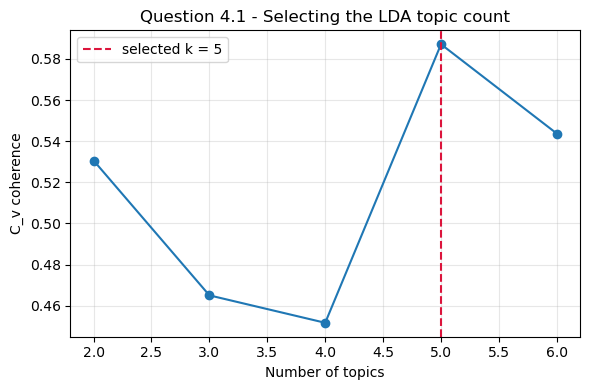

In [5]:
plt.figure(figsize=(6, 4))
plt.plot(list(coherence), list(coherence.values()), marker='o')
plt.axvline(best_k, color='crimson', linestyle='--', label=f'selected k = {best_k}')
plt.xlabel('Number of topics')
plt.ylabel('C_v coherence')
plt.title('Question 4.1 - Selecting the LDA topic count')
plt.grid(alpha=0.3)
plt.legend()
plt.tight_layout()
plt.savefig(OUT_DIR / 'q4_1_coherence.png', dpi=150)
plt.show()

### Topic word lists

In [6]:
topic_terms = {topic: lda.show_topic(topic, topn=10) for topic in range(best_k)}
topic_labels = {
    topic: ' / '.join(word for word, _ in terms[:3])
    for topic, terms in topic_terms.items()
}
topic_table = pd.DataFrame([
    {
        'topic': f'Topic {topic + 1}',
        'label': topic_labels[topic],
        'top_words': ', '.join(word for word, _ in topic_terms[topic]),
    }
    for topic in range(best_k)
])
topic_table.to_csv(OUT_DIR / 'q4_1_topic_words.csv', index=False)
topic_table

,topic,label,top_words
0,Topic 1,data / design / triangulation,"data, design, triangulation, study, researcher..."
1,Topic 2,instrument / cronbach_alpha / report,"instrument, cronbach_alpha, report, scale, rel..."
2,Topic 3,development / process / instructional,"development, process, instructional, developme..."
3,Topic 4,qualitative / value / paradigm,"qualitative, value, paradigm, researcher, stud..."
4,Topic 5,researcher / reflexivity / study,"researcher, reflexivity, study, experience, qu..."


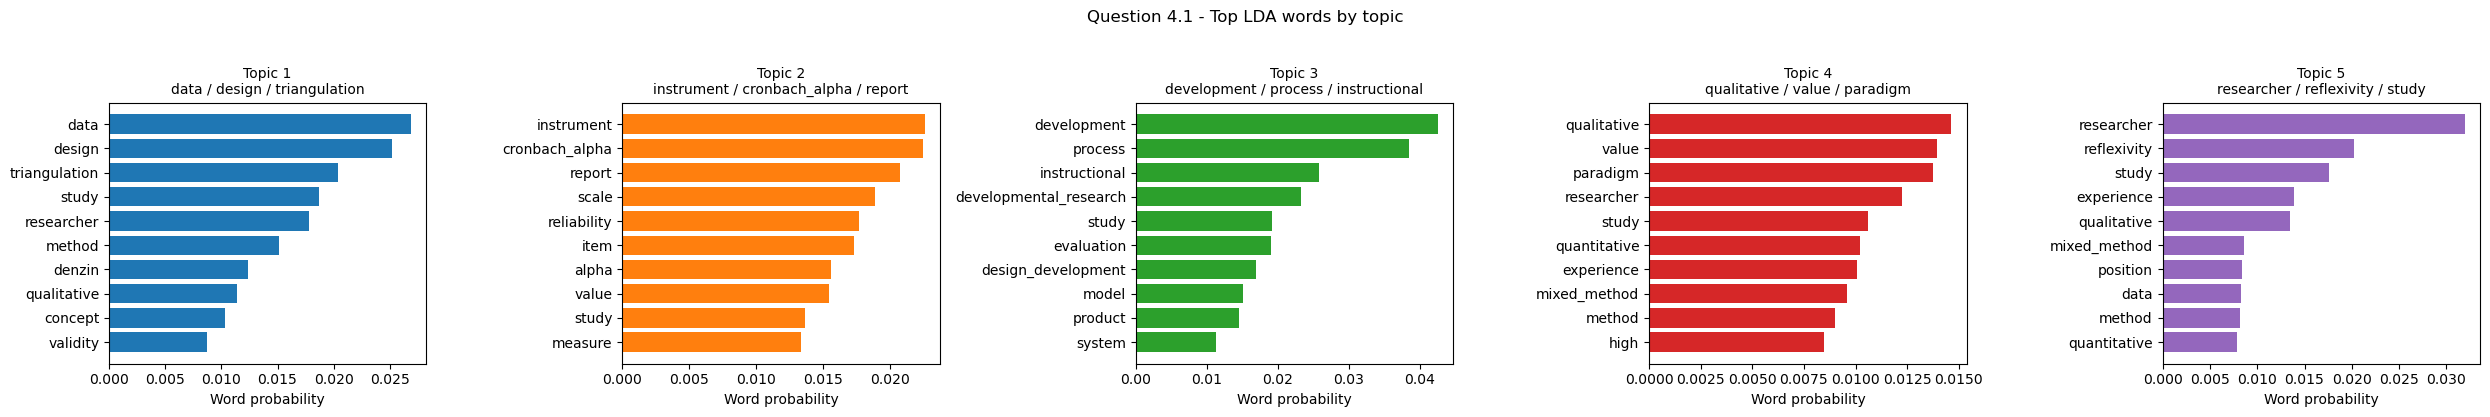

In [7]:
fig, axes = plt.subplots(1, best_k, figsize=(5 * best_k, 4), squeeze=False)
palette = sns.color_palette('tab10', best_k)
for topic, ax in enumerate(axes[0]):
    words, weights = zip(*topic_terms[topic])
    ax.barh(words[::-1], weights[::-1], color=palette[topic])
    ax.set_title(f'Topic {topic + 1}\n{topic_labels[topic]}', fontsize=10)
    ax.set_xlabel('Word probability')
fig.suptitle('Question 4.1 - Top LDA words by topic', y=1.03)
fig.tight_layout()
fig.savefig(OUT_DIR / 'q4_1_topic_words.png', dpi=150, bbox_inches='tight')
plt.show()

### Topic distribution per article

In [8]:
chunk_topic = np.array([
    [weight for _, weight in lda.get_document_topics(bow, minimum_probability=0)]
    for bow in corpus
])
columns = [f'Topic {topic + 1}: {topic_labels[topic]}' for topic in range(best_k)]
document_topic = (pd.DataFrame(chunk_topic, columns=columns)
                  .assign(article=chunk_sources)
                  .groupby('article', sort=False)
                  .mean())
document_topic.index.name = 'article'
document_topic.to_csv(OUT_DIR / 'q4_1_document_topic_distribution.csv')
document_topic.round(3)

,Topic 1: data / design / triangulation,Topic 2: instrument / cronbach_alpha / report,Topic 3: development / process / instructional,Topic 4: qualitative / value / paradigm,Topic 5: researcher / reflexivity / study
article,,,,,
research_1.txt,0.070,0.124,0.068,0.262,0.476
research_2.txt,0.073,0.006,0.031,0.111,0.779
research_3.txt,0.230,0.097,0.632,0.014,0.027
research_4.txt,0.062,0.792,0.000,0.107,0.039
research_5.txt,0.861,0.027,0.008,0.050,0.055


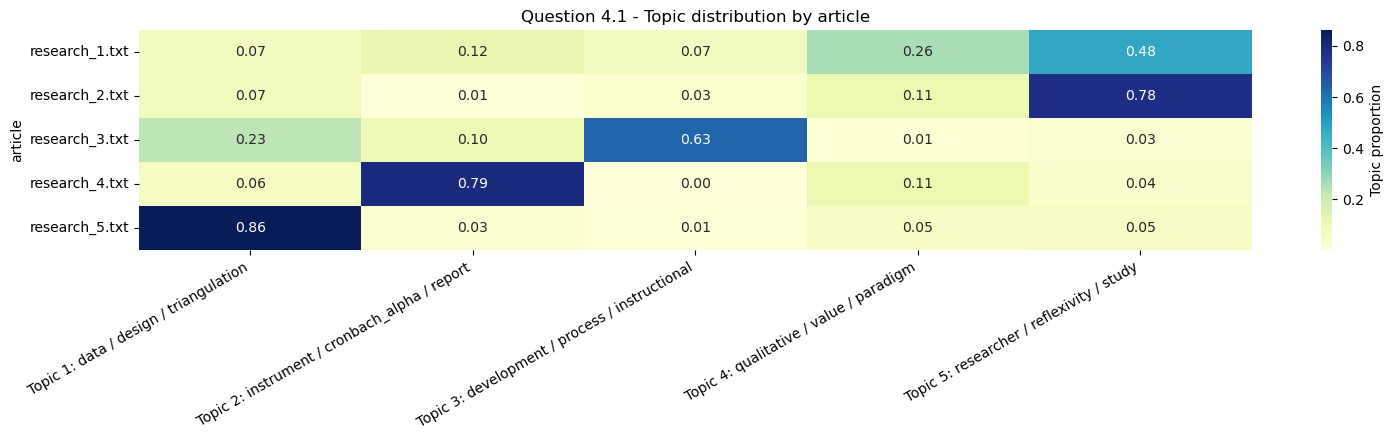

In [9]:
plt.figure(figsize=(2.3 * best_k + 4, 4.5))
sns.heatmap(document_topic, annot=True, fmt='.2f', cmap='YlGnBu',
            cbar_kws={'label': 'Topic proportion'})
plt.title('Question 4.1 - Topic distribution by article')
plt.xticks(rotation=30, ha='right')
plt.tight_layout()
plt.savefig(OUT_DIR / 'q4_1_document_topic_heatmap.png', dpi=150)
plt.show()

### Topic prevalence across the whole corpus

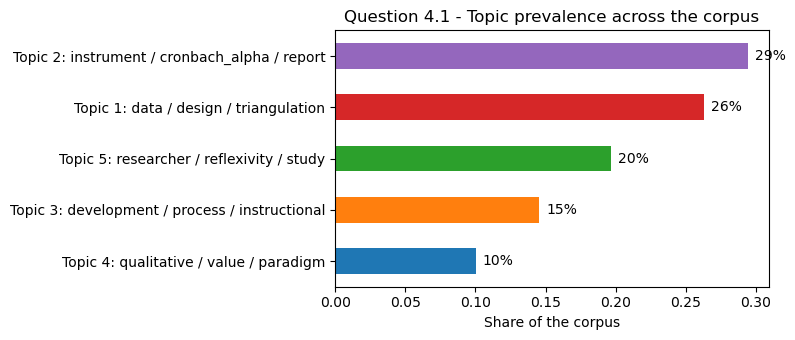

In [10]:
topic_share = pd.Series(chunk_topic.mean(axis=0), index=columns).sort_values()
ax = topic_share.plot.barh(figsize=(8, 3.5), color=sns.color_palette('tab10', best_k))
ax.set_xlabel('Share of the corpus')
ax.set_title('Question 4.1 - Topic prevalence across the corpus')
for y, v in enumerate(topic_share):
    ax.text(v + 0.005, y, f'{v:.0%}', va='center')
plt.tight_layout()
plt.savefig(OUT_DIR / 'q4_1_topic_prevalence.png', dpi=150)
plt.show()

## 4.2 Intertopic distance map (pyLDAvis)

In [11]:
panel = pyLDAvis.gensim_models.prepare(lda, corpus, dictionary, sort_topics=False)
pyLDAvis.save_html(panel, str(OUT_DIR / 'q4_2_intertopic_distance_map.html'))
print('Interactive map saved')

pyLDAvis.enable_notebook()
panel

Interactive map saved


PreparedData(topic_coordinates=              x         y  topics  cluster       Freq
topic                                                
0     -0.139329  0.023859       1        1  26.450254
1      0.112754 -0.192637       2        1  31.131047
2      0.172996  0.161821       3        1  14.631934
3     -0.036259 -0.029538       4        1   9.152632
4     -0.110162  0.036496       5        1  18.634134, topic_info=                       Term       Freq      Total Category  logprob  loglift
330             development  57.000000  57.000000  Default  30.0000  30.0000
47                  process  57.000000  57.000000  Default  29.0000  29.0000
110              researcher  85.000000  85.000000  Default  28.0000  28.0000
646           instructional  27.000000  27.000000  Default  27.0000  27.0000
797          cronbach_alpha  52.000000  52.000000  Default  26.0000  26.0000
..                      ...        ...        ...      ...      ...      ...
403               knowledge   7.809955  51.368736   Topic5  -5.1475  -0.2035
332                 finding   5.680072  13.783770   Topic5  -5.4659   0.7936
47                  process   7.699705  57.863773   Topic5  -5.1617  -0.3367
125                   value   7.274696  53.486374   Topic5  -5.2185  -0.3148
241  qualitative_researcher   5.598441  14.098406   Topic5  -5.4804   0.7566

[311 rows x 6 columns], token_table=      Topic      Freq        Term
term                             
623       1  0.779094     ability
623       2  0.086566     ability
623       4  0.086566     ability
748       1  0.840120      accept
793       2  0.758381  acceptable
...     ...       ...         ...
210       5  0.062500        work
559       5  0.859736   worldview
126       1  0.267354       write
126       4  0.401030       write
126       5  0.267354       write

[501 rows x 3 columns], R=30, lambda_step=0.01, plot_opts={'xlab': 'PC1', 'ylab': 'PC2'}, topic_order=[1, 2, 3, 4, 5])